<p>
<font size='5' face='Georgia, Arial'>IIC2233 Apunte Programación Avanzada</font><br>
<font size='1'> Modificado en 2019-1 al 2026-2 por Equipo Docente IIC2233. </font>
</p>

# Tabla de contenidos

1. [Cliente de un servicio web](#cliente)
    1. [Consumir una API con GET](#get)
    2. [Parámetros](#parametros)
    3. [Formatos de respuesta](#respuesta)
    4. [Enviar JSON con POST](#post)
    5. [Autenticación](#autenticacion)
    6. [Caso aplicado: GitHub](#github)
2. [Resumen](#resumen)

<a id="cliente"></a>
## Cliente de un servicio web

La biblioteca `requests` permite enviar solicitudes HTTP desde Python. Para instalarla en el mismo entorno del kernel recomendamos usar `%pip` dentro del notebook o un archivo de dependencias.

Casi todas las solicitudes a servicios externos deben incluir `timeout` para evitar esperas indefinidas. También debemos comprobar el código de estado antes de interpretar la respuesta.

In [1]:
%pip install requests


[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: /Users/tamavidal/Desktop/Progra Avanzada/2026-2/contenidos-2026-2/semana-10-serializacion_y_networkin_1/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Para generar una petición mediante `GET` usamos el método `get(url)` que recibe por argumento el llamado al recurso.


In [2]:
import requests


url = "https://api.github.com/repos/IIC2233/Syllabus/contents/Actividades"
respuesta = requests.get(url, timeout=10)
respuesta.raise_for_status()

Luego podemos usar `.status_code` para saber el código  de estado de la consulta.

In [3]:
print(f'Status: {respuesta.status_code}')

Status: 200


In [4]:
data = respuesta.json()
for archivo in data:
    print(archivo["name"], archivo["html_url"])

.keep https://github.com/IIC2233/Syllabus/blob/main/Actividades/.keep
ACDiag_1 https://github.com/IIC2233/Syllabus/tree/main/Actividades/ACDiag_1
ACDiagnostico2 https://github.com/IIC2233/Syllabus/tree/main/Actividades/ACDiagnostico2


<a id="get"></a>
## Ejemplo consumiendo una API con `GET`

Usaremos la API educativa [DummyJSON](https://dummyjson.com/), que entrega datos ficticios.

Una API suele documentar una **URL base** y distintos **endpoints**. Por ejemplo:

- `products/`: productos;
- `recipes/`: recetas;
- `carts/`: carros de compra;
- `image/`: imágenes generadas.

Los datos y resultados de un servicio externo pueden cambiar, por lo que siempre se debe validar la respuesta.

In [5]:
import requests


BASE = "https://dummyjson.com/"
endpoint_1 = "recipes/"

respuesta = requests.get(BASE + endpoint_1, timeout=10)
respuesta.raise_for_status()
print(respuesta.status_code)

200


Ahora vamos a ver el contenido de la consulta

In [6]:
data = respuesta.json()
print("Llaves: ", data.keys())

Llaves:  dict_keys(['recipes', 'total', 'skip', 'limit'])


In [7]:
data["total"]

50

In [8]:
data['recipes'][0]

{'id': 1,
 'name': 'Classic Margherita Pizza',
 'ingredients': ['Pizza dough',
  'Tomato sauce',
  'Fresh mozzarella cheese',
  'Fresh basil leaves',
  'Olive oil',
  'Salt and pepper to taste'],
 'instructions': ['Preheat the oven to 475°F (245°C).',
  'Roll out the pizza dough and spread tomato sauce evenly.',
  'Top with slices of fresh mozzarella and fresh basil leaves.',
  'Drizzle with olive oil and season with salt and pepper.',
  'Bake in the preheated oven for 12-15 minutes or until the crust is golden brown.',
  'Slice and serve hot.'],
 'prepTimeMinutes': 20,
 'cookTimeMinutes': 15,
 'servings': 4,
 'difficulty': 'Easy',
 'cuisine': 'Italian',
 'caloriesPerServing': 300,
 'tags': ['Pizza', 'Italian'],
 'userId': 166,
 'image': 'https://cdn.dummyjson.com/recipe-images/1.webp',
 'rating': 4.6,
 'reviewCount': 98,
 'mealType': ['Dinner']}

Cómo podemos notar, nos entregó la información completa de una receta.

Ahora vamos a hacer una consulta al endpoint de `"products/"`.

In [9]:
endpoint_2 = "products/"

respuesta = requests.get(BASE + endpoint_2, timeout=10)
respuesta.raise_for_status()

data = respuesta.json()
[producto["title"] for producto in data["products"][:2]]

['Essence Mascara Lash Princess', 'Eyeshadow Palette with Mirror']

<a id="parametros"></a>
### Parámetros de una consulta

Los parámetros de consulta deben enviarse mediante `params`. `requests` se encarga de codificar espacios y caracteres especiales correctamente.

DummyJSON acepta, entre otros:

- `limit`: cantidad de elementos;
- `select`: campos solicitados;
- `q`: texto de búsqueda en endpoints de búsqueda.

In [10]:
endpoint_3 = "recipes/search/"
parametros = {"limit": 5, "select": "name", "q": "chicken"}

respuesta = requests.get(
    BASE + endpoint_3,
    params=parametros,
    timeout=10,
)
respuesta.raise_for_status()

print("URL codificada:", respuesta.url)
data = respuesta.json()
data["recipes"]

URL codificada: https://dummyjson.com/recipes/search?limit=5&select=name&q=chicken


[{'id': 4, 'name': 'Chicken Alfredo Pasta'},
 {'id': 5, 'name': 'Mango Salsa Chicken'},
 {'id': 11, 'name': 'Chicken Biryani'},
 {'id': 12, 'name': 'Chicken Karahi'},
 {'id': 20, 'name': 'Butter Chicken (Murgh Makhani)'}]

In [11]:
parametros = {"limit": 3, "select": "name", "q": "chicken"}
respuesta = requests.get(
    BASE + endpoint_3,
    params=parametros,
    timeout=10,
)
respuesta.raise_for_status()
respuesta.json()["recipes"]

[{'id': 4, 'name': 'Chicken Alfredo Pasta'},
 {'id': 5, 'name': 'Mango Salsa Chicken'},
 {'id': 11, 'name': 'Chicken Biryani'}]

Algunos valores forman parte de la **ruta**, mientras otros pertenecen al *query string*. En el endpoint de imágenes, tamaño y colores son segmentos de ruta; `text` y `fontFamily` son parámetros de consulta.

Conviene distinguir ambos mecanismos y dejar que `requests` codifique los parámetros mediante `params`.

In [12]:
consulta = "image/"
porte = "400x200/"
color_fondo = "82944b/"
color_fuente = "d4d2bc"
endpoint_4 = consulta + porte + color_fondo + color_fuente

parametros = {
    "text": "Todos somos Pepa lovers",
    "fontFamily": "ubuntu",
}

respuesta_imagen = requests.get(
    BASE + endpoint_4,
    params=parametros,
    timeout=10,
)
respuesta_imagen.raise_for_status()

content_type = respuesta_imagen.headers.get("Content-Type", "")
if not content_type.startswith("image/"):
    raise ValueError(f"Se esperaba una imagen, se recibió {content_type}")

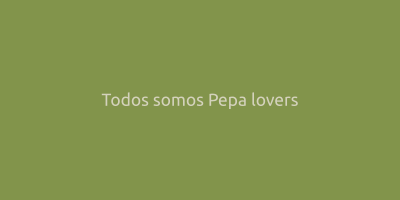

In [13]:
from IPython.display import display, Image
from pathlib import Path


ruta_imagen = Path("data") / "img_personalizada.png"
ruta_imagen.parent.mkdir(exist_ok=True)
ruta_imagen.write_bytes(respuesta_imagen.content)

display(Image(filename=str(ruta_imagen)))

Te invitamos a cambiar los valores del _endpoint_ y los parámetros para crear tus propias imágenes. 

<a id="respuesta"></a>
### Formatos de respuesta

El código de estado no indica el formato del cuerpo. Antes de interpretarlo debemos revisar `Content-Type`. Una respuesta puede contener JSON, texto, HTML, una imagen o ningún contenido.

In [14]:
import requests


BASE = "https://dummyjson.com/"
endpoint_1 = "recipes/"
parametros = {"limit": 10, "select": "name"}

respuesta = requests.get(
    BASE + endpoint_1,
    params=parametros,
    timeout=10,
)
respuesta.raise_for_status()
respuesta.json()

{'recipes': [{'id': 1, 'name': 'Classic Margherita Pizza'},
  {'id': 2, 'name': 'Vegetarian Stir-Fry'},
  {'id': 3, 'name': 'Chocolate Chip Cookies'},
  {'id': 4, 'name': 'Chicken Alfredo Pasta'},
  {'id': 5, 'name': 'Mango Salsa Chicken'},
  {'id': 6, 'name': 'Quinoa Salad with Avocado'},
  {'id': 7, 'name': 'Tomato Basil Bruschetta'},
  {'id': 8, 'name': 'Beef and Broccoli Stir-Fry'},
  {'id': 9, 'name': 'Caprese Salad'},
  {'id': 10, 'name': 'Shrimp Scampi Pasta'}],
 'total': 50,
 'skip': 0,
 'limit': 10}

Una respuesta también puede contener datos binarios. Conservamos la respuesta de la imagen anterior para inspeccionar su tipo y tamaño sin imprimir todos sus bytes:

In [15]:
content_type = respuesta_imagen.headers.get("Content-Type", "")
print("Content-Type:", content_type)
print(f"Respuesta binaria de {len(respuesta_imagen.content)} bytes")

Content-Type: image/png
Respuesta binaria de 5236 bytes


<a id="post"></a>
### Enviar JSON con `POST`

`POST` solicita que un recurso procese el contenido enviado. Frecuentemente se usa para crear recursos, aunque esa no es su única semántica.

Cuando la API espera JSON, utilizamos el argumento `json=payload`. `requests` serializa el diccionario y agrega `Content-Type: application/json`. El argumento `data=` tiene otra finalidad y, al recibir un diccionario, normalmente envía un formulario.

In [16]:
import requests


BASE = "https://dummyjson.com/"
endpoint_5 = "products/add"

payload = {
    "title": "Comida de Pepa",
    "description": "Alimento esencial de una tortuga",
    "price": 2233,
    "rating": 5,
}

respuesta = requests.post(
    BASE + endpoint_5,
    json=payload,
    timeout=10,
)
respuesta.raise_for_status()

In [17]:
# Vemos que obtenemos un código de que nuestro producto fue creado
print(respuesta.status_code)
print(respuesta.reason)

201
Created


In [18]:
# Esta API nos retorna un JSON con el mismo recurso creado, nótese que se le asignó un id al artículo
data = respuesta.json() 
print(data.keys())

dict_keys(['id', 'title', 'price', 'rating', 'description'])


In [19]:
data

{'id': 195,
 'title': 'Comida de Pepa',
 'price': 2233,
 'rating': 5,
 'description': 'Alimento esencial de una tortuga'}

<a id="autenticacion"></a>
### Autenticación mediante headers

Los headers transmiten metadatos de la solicitud. Uno de sus usos es enviar credenciales, por ejemplo un token mediante `Authorization`.

Los nombres, formato y permisos dependen de cada API. Un token debe tratarse como una contraseña: no debe imprimirse, guardarse en el notebook ni publicarse en Git.

In [20]:
url = "https://dummyjson.com/auth/login"
payload = {
    "username": "emilys",
    "password": "emilyspass",
    "expiresInMins": 30,
}

respuesta = requests.post(url, json=payload, timeout=10)
respuesta.raise_for_status()
TOKEN = respuesta.json()["accessToken"]

print("Token obtenido correctamente; no se muestra por seguridad.")

Token obtenido correctamente; no se muestra por seguridad.


In [21]:
url = "https://dummyjson.com/auth/me"
headers = {"Authorization": f"Bearer {TOKEN}"}

respuesta = requests.get(url, headers=headers, timeout=10)
respuesta.raise_for_status()
respuesta.status_code

200

In [22]:
usuario = respuesta.json()
{
    "id": usuario["id"],
    "username": usuario["username"],
    "email": usuario["email"],
    "role": usuario["role"],
}

{'id': 1,
 'username': 'emilys',
 'email': 'emily.johnson@x.dummyjson.com',
 'role': 'admin'}

In [23]:
url = "https://dummyjson.com/auth/me"
respuesta = requests.get(url, timeout=10)

print(respuesta.status_code)
print(respuesta.reason)

401
Unauthorized


<a id="github"></a>
### Caso aplicado: API de GitHub

El siguiente ejemplo prepara la creación de una *issue* mediante la API de GitHub.

Requisitos:

1. Definir el propietario y repositorio.
2. Crear un token de acceso de permisos específicos con `Issues: write`.
3. Guardar el token en la variable de entorno `GITHUB_TOKEN`. Nunca debe escribirse directamente en el notebook.

La API espera un cuerpo JSON. `requests` permite enviarlo directamente con `json=body`.

In [24]:
import os
import requests


github_owner = "TU_USUARIO_O_ORGANIZACION"
github_repo = "TU_REPOSITORIO"
token = os.environ.get("GITHUB_TOKEN")
respuesta = None

body = {
    "title": "Creando una issue con la API",
    "body": "Issue creada desde Python.",
}

if token is None:
    print("Define la variable de entorno GITHUB_TOKEN antes de ejecutar.")
else:
    headers = {
        "Authorization": f"Bearer {token}",
        "Accept": "application/vnd.github+json",
        "X-GitHub-Api-Version": "2026-03-10",
    }
    url = f"https://api.github.com/repos/{github_owner}/{github_repo}/issues"
    respuesta = requests.post(
        url,
        json=body,
        headers=headers,
        timeout=10,
    )

Define la variable de entorno GITHUB_TOKEN antes de ejecutar.


Si los datos son correctos, GitHub responde `201 Created`. El código siguiente evita asumir que la solicitud fue enviada cuando falta el token.

In [25]:
if respuesta is None:
    print("Solicitud no enviada.")
elif respuesta.status_code == 201:
    print("Issue creada:", respuesta.json()["html_url"])
else:
    print("No fue posible crear la issue.")
    print("Status:", respuesta.status_code)
    print("Detalle:", respuesta.text[:300])

Solicitud no enviada.


Para seguir practicando:

- Explora otros endpoints de [DummyJSON](https://dummyjson.com/).
- Consulta películas mediante [OMDb API](https://www.omdbapi.com/).
- Busca información en [PokéAPI](https://pokeapi.co/docs/v2#pokemon).

Revisa siempre la documentación, los límites de uso y los requisitos de autenticación.

El envío concurrente de solicitudes, sus beneficios y sus riesgos se desarrolla en el notebook [bonus de concurrencia](6-bonus_race_conditions.ipynb).

<a id="resumen"></a>
## Resumen

Una API web suele definir:

- URL base y endpoints;
- métodos permitidos;
- parámetros de ruta y consulta;
- formato del cuerpo;
- autenticación;
- respuestas y códigos de estado.

Usa `params=` para el *query string*, `json=` para cuerpos JSON, `headers=` para metadatos y credenciales, y `timeout=` para limitar la espera.

Antes de interpretar una respuesta, comprueba su estado y `Content-Type`. El cuerpo puede ser JSON, texto, HTML, datos binarios o estar ausente.